In [ ]:
# 전기 Panel.csv
# 이 데이터는 산업 설비(특히 컨베이어·회전 기구·펌프 등 모터 구동 설비)의 전기 패널에서 수집한 전류 시계열 데이터입니다.
# 데이터 도메인 설명
# 이 데이터는 **산업용 전기 패널(Electrical Panel / MCC)**에서 측정한 모터 전류 데이터로, 예지정비(Predictive Maintenance), 상태 모니터링(Condition Monitoring), 산업 IoT(IIoT) 영역에서 자주 사용되는 유형입니다.

# 모터 전류는 부하 상태, 기계적 이상(잼, 벨트 슬립, 베어링 마모, 정렬 불량, 과부하), 전기적 이상(위상 불평형, 권선 문제 등)을 비침습적으로 파악할 수 있는 중요한 지표입니다.
# 컨베이어, 회전 기구, 펌프처럼 연속 운전되는 설비에서 전류 변화를 모니터링하면 고장 전에 이상 징후를 잡을 수 있습니다.
# 파일명 23_전기Panel.csv와 컬럼 구성(설비번호 + 시퀀스 + 여러 모터 전류)을 보면, 여러 설비(또는 동일 설비의 다른 구간/패널)를 순차적으로 샘플링한 데이터로 보입니다.
# 값의 범위가 대부분 0~0.7 정도로 작아, 실제 암페어(A) 값이거나 스케일링/정규화된 값, 또는 특정 단위(예: 저전류 센서 출력)일 가능성이 있습니다. 해석 시 센서 사양이나 스케일 팩터 확인이 필요합니다.

# 이러한 데이터는 Motor Current Signature Analysis(MCSA), RMS 전류 트렌딩, 이상 탐지 모델 학습 등에 활용됩니다.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
EP = '..//data//23_전기Panel.csv'   # 설비번호·시퀀스·컨베이어전류·회전A/B전류·펌프A/B전류
df = pd.read_csv(EP)

In [ ]:
# ── [개념] 설비1·컨베이어전류 이동통계·변화점 ──────────────────────────────

In [4]:
df.columns

Index(['설비번호', '시퀀스', '컨베이어전류', '회전A전류', '회전B전류', '펌프A전류', '펌프B전류'], dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1250 entries, 0 to 1249
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   설비번호    1250 non-null   int64  
 1   시퀀스     1250 non-null   int64  
 2   컨베이어전류  1250 non-null   float64
 3   회전A전류   1250 non-null   float64
 4   회전B전류   1250 non-null   float64
 5   펌프A전류   1250 non-null   float64
 6   펌프B전류   1250 non-null   float64
dtypes: float64(5), int64(2)
memory usage: 68.5 KB


In [6]:
df.describe()

,설비번호,시퀀스,컨베이어전류,회전A전류,회전B전류,펌프A전류,펌프B전류
count,1250.00000,1250.000000,1250.000000,1250.000000,1250.000000,1250.000000,1250.0
mean,3.00000,125.500000,0.041642,0.041254,0.700998,0.004517,0.0
std,1.41478,72.197091,0.093281,0.020706,0.021206,0.005590,0.0
min,1.00000,1.000000,0.000000,0.000000,0.002100,0.000000,0.0
25%,2.00000,63.000000,0.000000,0.049600,0.703700,0.000000,0.0
50%,3.00000,125.500000,0.000000,0.052000,0.703700,0.000000,0.0
75%,4.00000,188.000000,0.000000,0.052300,0.703700,0.010800,0.0
max,5.00000,250.000000,0.269500,0.052300,0.740700,0.029100,0.0


In [7]:
df['설비번호'].value_counts()

설비번호
1    250
2    250
3    250
4    250
5    250
Name: count, dtype: int64

In [9]:
u1=df[df['설비번호'] == 1].copy()

In [10]:
u1.index

RangeIndex(start=0, stop=250, step=1)

In [12]:
u1.sort_values('시퀀스')

,설비번호,시퀀스,컨베이어전류,회전A전류,회전B전류,펌프A전류,펌프B전류
0,1,1,0.0000,0.0523,0.7037,0.0125,0.0
1,1,2,0.0000,0.0523,0.7037,0.0115,0.0
2,1,3,0.0000,0.0523,0.7037,0.0102,0.0
3,1,4,0.0000,0.0523,0.7037,0.0100,0.0
4,1,5,0.0000,0.0523,0.7037,0.0100,0.0
...,...,...,...,...,...,...,...
245,1,246,0.2482,0.0500,0.7030,0.0100,0.0
246,1,247,0.2482,0.0509,0.7037,0.0100,0.0
247,1,248,0.2485,0.0509,0.7037,0.0100,0.0
248,1,249,0.2489,0.0512,0.7037,0.0100,0.0


In [13]:
u1=u1.sort_values('시퀀스').reset_index(drop=True)

In [14]:
# 변화량

In [16]:
u1['ma10']=u1['컨베이어전류'].rolling(10).mean()

In [17]:
u1

,설비번호,시퀀스,컨베이어전류,회전A전류,회전B전류,펌프A전류,펌프B전류,ma10
0,1,1,0.0000,0.0523,0.7037,0.0125,0.0,NaN
1,1,2,0.0000,0.0523,0.7037,0.0115,0.0,NaN
2,1,3,0.0000,0.0523,0.7037,0.0102,0.0,NaN
3,1,4,0.0000,0.0523,0.7037,0.0100,0.0,NaN
4,1,5,0.0000,0.0523,0.7037,0.0100,0.0,NaN
...,...,...,...,...,...,...,...,...
245,1,246,0.2482,0.0500,0.7030,0.0100,0.0,0.13979
246,1,247,0.2482,0.0509,0.7037,0.0100,0.0,0.13908
247,1,248,0.2485,0.0509,0.7037,0.0100,0.0,0.13840
248,1,249,0.2489,0.0512,0.7037,0.0100,0.0,0.13776


In [18]:
# resiuals(잔차) : 평균과의 차

In [19]:
u1['컨베이어전류'] - u1['ma10']

0          NaN
1          NaN
2          NaN
3          NaN
4          NaN
        ...   
245    0.10841
246    0.10912
247    0.11010
248    0.11114
249    0.08856
Length: 250, dtype: float64

In [20]:
resid1=u1['컨베이어전류'] - u1['ma10']

In [22]:
# 임계치(threshold) 잡기

In [23]:
thr1=2*resid1.std()

In [25]:
resid1.abs() > thr1

0      False
1      False
2      False
3      False
4      False
       ...  
245     True
246     True
247     True
248     True
249     True
Length: 250, dtype: bool

In [26]:
resid1[resid1.abs() > thr1]

223    0.22205
224    0.19979
225    0.17257
226    0.14414
227    0.11861
228    0.09272
239   -0.20331
240   -0.20718
241   -0.18165
242   -0.15612
244    0.10770
245    0.10841
246    0.10912
247    0.11010
248    0.11114
249    0.08856
dtype: float64

In [27]:
len(resid1[resid1.abs() > thr1])

16

In [3]:
# 실습1 9시 30분까지

In [28]:
# ── [실습 1] 데이터 불러오기와 단일 설비 신호 그리기 (설비2·컨베이어전류) ────

In [29]:
u2 = df[df['설비번호'] == 2].copy().sort_values('시퀀스').reset_index(drop=True)

In [30]:
print(df.shape, df['설비번호'].unique())       # (1250, 7) [1 2 3 4 5]

(1250, 7) [1 2 3 4 5]


In [31]:
print(u2.shape)                                # (250, 7)

(250, 7)


In [33]:
u2['ma10']=u2['컨베이어전류'].rolling(10).mean()

In [34]:
u2

,설비번호,시퀀스,컨베이어전류,회전A전류,회전B전류,펌프A전류,펌프B전류,ma10
0,2,1,0.0,0.0496,0.7037,0.0,0.0,NaN
1,2,2,0.0,0.0496,0.7037,0.0,0.0,NaN
2,2,3,0.0,0.0496,0.7037,0.0,0.0,NaN
3,2,4,0.0,0.0496,0.7037,0.0,0.0,NaN
4,2,5,0.0,0.0496,0.7037,0.0,0.0,NaN
...,...,...,...,...,...,...,...,...
245,2,246,0.0,0.0523,0.7037,0.0,0.0,0.0
246,2,247,0.0,0.0523,0.7037,0.0,0.0,0.0
247,2,248,0.0,0.0523,0.7037,0.0,0.0,0.0
248,2,249,0.0,0.0523,0.7037,0.0,0.0,0.0


In [35]:
resid2=u2['컨베이어전류'] - u2['ma10']

In [36]:
resid2

0      NaN
1      NaN
2      NaN
3      NaN
4      NaN
      ... 
245    0.0
246    0.0
247    0.0
248    0.0
249    0.0
Length: 250, dtype: float64

In [37]:
thr2=2*resid2.std()

In [38]:
resid2.abs()

0      NaN
1      NaN
2      NaN
3      NaN
4      NaN
      ... 
245    0.0
246    0.0
247    0.0
248    0.0
249    0.0
Length: 250, dtype: float64

In [39]:
thr2

np.float64(0.053562098477686)

In [40]:
resid2.abs() > thr2

0      False
1      False
2      False
3      False
4      False
       ...  
245    False
246    False
247    False
248    False
249    False
Length: 250, dtype: bool

In [41]:
resid2[resid2.abs() > thr2]

37     0.12258
127    0.20754
128    0.08602
135    0.19900
136    0.18135
138   -0.05598
139   -0.05598
140   -0.05598
141   -0.05598
142   -0.05598
143   -0.05598
144   -0.05598
dtype: float64

In [42]:
len(resid2[resid2.abs() > thr2])

12

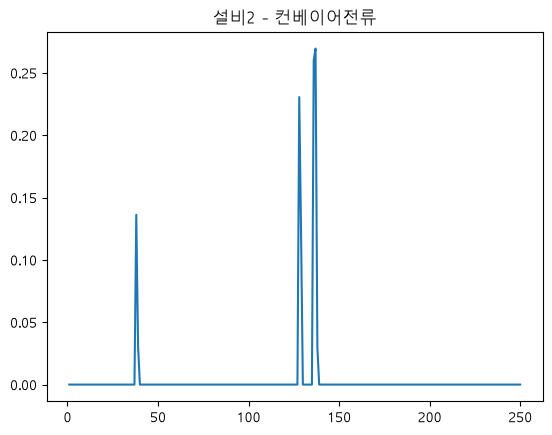

In [43]:
plt.rcParams['font.family']='Malgun Gothic'
plt.plot(u2['시퀀스'], u2['컨베이어전류']); plt.title('설비2 - 컨베이어전류')
plt.show()